# 03 · Two-stage anchor-based detector: Faster R-CNN

Covers the *Two-stage Anchor-based* checkpoint.

**Same protocol as notebook 02:** the identical exported training set (official `train` clips, every 5th
frame, ignored regions masked, frames at a 1280 px longer side), the same evaluator on all 2 846 frames of
the official `val` clips, seed 42, COCO-pretrained weights.

**Model:** torchvision Faster R-CNN, ResNet-50 + FPN, input 1280×720. Only the classifier (8 classes +
background) is new. Training: SGD, lr 0.005 (linear scaling of 0.02 @ batch 16 to batch 4), 500-iteration
warm-up, lr × 0.1 for the last 2 epochs, mixed precision, horizontal flip as the only augmentation.

**Experiments**

| id | what changes | type | motivation |
|---|---|---|---|
| F0 | torchvision defaults: anchors 32–512 px, Smooth L1 box loss | training | baseline |
| F0 → inference | 500 detections/image, score threshold 0.001, then 1 000 → 3 000 RPN proposals | test-time, same weights | up to 180 objects per frame (01, §3.3); the metric scores 500 detections |
| F1 | anchors 16–256 px | training | default anchors cannot match any object < 16 px (01, §4.3) |
| F2 | F1 + GIoU instead of Smooth L1 in the RoI head | training, **loss** | a scale-invariant overlap loss for small boxes |

**Runtime:** GPU. Run with `SMOKE = True` first, then `SMOKE = False`. Each training run checkpoints
after every epoch; after a disconnect just run everything again: finished runs are skipped, the interrupted one resumes.

## 1. Setup

In [1]:
# --- Download the competition data -----------------------------------------------------
# The Kaggle token is read from Colab Secrets (key icon -> KAGGLE_API_TOKEN, notebook access on);
# it is never written into the notebook.
import os, subprocess
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"
print("Downloading competition dataset...")
subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", "/content", "-q"], check=True)
print("Extracting data...")
os.makedirs("/content/data", exist_ok=True)
subprocess.run(["unzip", "-q", "-o", f"/content/{COMPETITION}.zip", "-d", "/content/data"], check=True)
os.remove(f"/content/{COMPETITION}.zip")
print("Done! The /content/data/train folder has been created.")

Extracting data...
Done! The /content/data/train folder has been created.


In [3]:
# --- Imports and configuration -------------------------------------------------------
import json, random, time
from dataclasses import asdict, replace
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torchvision

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, viz as V, yolo_export as YX, ultra as U
from vdet import tv_detect as TV, analysis as AN
from vdet.paths import find_data_root, default_work_dir

SMOKE = False               # True: tiny run to test the pipeline. False: the real experiments.
RUN = ["F0", "F1", "F2"]   # training runs for this session (finished ones are skipped)

SEED = 42
EPOCHS = 1 if SMOKE else 8
BATCH = 4                  # fits a 16 GB T4 at 1280x720 with mixed precision
TRAIN_STEP, VAL_MONITOR_STEP, EXPORT_SIDE = 5, 3, 1280   # identical to notebook 02
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORKERS = min(4, os.cpu_count() or 2)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
TAG = "_smoke" if SMOKE else ""
RUNS_DIR = WORK_DIR / f"runs_frcnn{TAG}"
YOLO_DS = (Path("/tmp") if IN_KAGGLE else Path("/content") if IN_COLAB else WORK_DIR) / f"yolo_ds{TAG}"   # shared with notebook 02
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
log = U.ResultsLog(WORK_DIR / f"results_frcnn{TAG}.json")

TRAIN_CFG = TV.TrainConfig(epochs=EPOCHS, batch=BATCH, milestones=(max(1, EPOCHS - 2),), workers=WORKERS, seed=SEED,
                           max_iters_per_epoch=20 if SMOKE else None)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "| workers", WORKERS)

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device Tesla T4 | workers 2


## 2. Data:

In [2]:
# --- Environment detection and paths (same as notebooks 01, 02) -------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"   # Colab only: used to download the data

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:  # anywhere on Google Drive (unzipping often adds an extra visdrone-det/ level)
        for depth in range(0, 4):
            hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + "vdet/__init__.py"))
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet/ not found on Google Drive: upload the visdrone-det folder to MyDrive")
    if IN_KAGGLE:
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # results survive disconnects
    if not os.path.exists("/content/data/train"):
        # Kaggle API token, never written into the notebook (it goes to GitHub):
        # Colab sidebar -> key icon (Secrets) -> name KAGGLE_API_TOKEN, value KGAT_..., notebook access ON.
        # Fallback: a legacy kaggle.json in the MyDrive root.
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !pip -q install -U kaggle
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

for pkg, mod in [("pycocotools", "pycocotools")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

Mounted at /content/drive
repo: /content/drive/MyDrive/visdrone-det


In [4]:
tv = D.load_train_val(DATA_ROOT)
im = tv.images
train_keys = D.subsample_frames(im[im.split == "train"], TRAIN_STEP).key
monitor_keys = D.subsample_frames(im[im.split == "val"], VAL_MONITOR_STEP).key   # per-epoch mAP curve
eval_keys = im[im.split == "val"].key                                             # final numbers: all val frames
if SMOKE:
    train_keys = D.subsample_frames(im[im.split == "train"], 200).key
    monitor_keys = eval_keys = D.subsample_frames(im[im.split == "val"], 100).key
train, monitor, val = tv.subset(train_keys), tv.subset(monitor_keys), tv.subset(eval_keys)

if not (YOLO_DS / "data.yaml").exists():      # already there if notebook 02 ran in this session
    display(YX.export_yolo_dataset(train, monitor, YOLO_DS, mask_train=True, mask_val=False, max_side=EXPORT_SIDE))
train_ds = TV.ExportedDetDataset(YOLO_DS, "train")
print("training frames:", len(train_ds), "| monitor frames:", len(monitor.images), "| eval frames:", len(val.images))

export train:   0%|          | 0/4868 [00:00<?, ?it/s]

export val:   0%|          | 0/951 [00:00<?, ?it/s]

,images,masked_images,boxes,dropped_boxes
train,4868,3644,220357,2522
val,951,0,38206,0


training frames: 4868 | monitor frames: 951 | eval frames: 2846


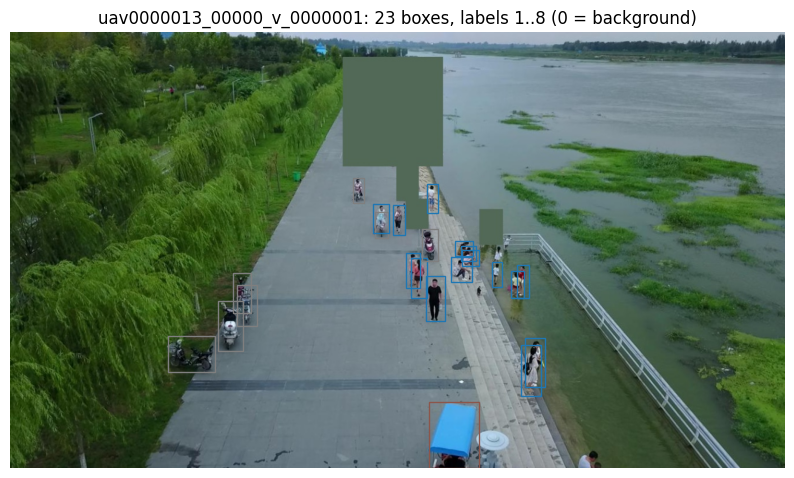

In [5]:
# Check what the model receives: one training sample with its targets (after the random flip)
img, tgt = train_ds[0]
fig, ax = plt.subplots(figsize=(10, 6)); ax.imshow(img.permute(1, 2, 0)); ax.axis("off")
for (x1, y1, x2, y2), l in zip(tgt["boxes"].tolist(), tgt["labels"].tolist()):
    ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=V.COLORS[l - 1], lw=1))
ax.set_title(f"{train_ds.keys[0]}: {len(tgt['boxes'])} boxes, labels 1..8 (0 = background)"); plt.show()

## 3. Experiments
Experiments lists only what differs from the torchvision defaults in `TV.FRCNNConfig`.
During training the model is evaluated after every epoch on the monitor subset with the
evaluation inference settings, which gives the mAP-over-training curve needed later for the RT-DETR comparison.

In [6]:
EXPERIMENTS = {
    "F0": {},
    "F1": dict(anchor_sizes=(16, 32, 64, 128, 256)),
    "F2": dict(anchor_sizes=(16, 32, 64, 128, 256), box_loss="giou", box_loss_weight=10.0),
}
# Test-time settings evaluated on the same trained weights (no retraining)
INFERENCE = {
    "default (100 det, score 0.05, 1000 prop.)": dict(detections_per_img=100, score_thresh=0.05, rpn_pre_nms_top_n=1000, rpn_post_nms_top_n=1000),
    "500 det, score 0.001, 1000 prop.":          dict(detections_per_img=500, score_thresh=0.001, rpn_pre_nms_top_n=1000, rpn_post_nms_top_n=1000),
    "500 det, score 0.001, 3000 prop.":          dict(detections_per_img=500, score_thresh=0.001, rpn_pre_nms_top_n=3000, rpn_post_nms_top_n=3000),
}
MONITOR_INF = INFERENCE["500 det, score 0.001, 1000 prop."]
cfgs = {k: replace(TV.FRCNNConfig(), **v) for k, v in EXPERIMENTS.items()}
pd.DataFrame({k: asdict(c) for k, c in cfgs.items()}).T[["anchor_sizes", "box_loss", "box_loss_weight",
    "rpn_post_nms_top_n_train", "box_batch_size_per_image", "box_positive_fraction"]]

,anchor_sizes,box_loss,box_loss_weight,rpn_post_nms_top_n_train,box_batch_size_per_image,box_positive_fraction
F0,"(32, 64, 128, 256, 512)",smooth_l1,1.0,2000,512,0.25
F1,"(16, 32, 64, 128, 256)",smooth_l1,1.0,2000,512,0.25
F2,"(16, 32, 64, 128, 256)",giou,10.0,2000,512,0.25


In [7]:
ev_monitor = E.DetectionEvaluator(monitor)
ev = E.DetectionEvaluator(val)

def monitor_fn(model):
    """mAP on the monitor subset after an epoch (reads the downscaled export: fast)."""
    TV.set_inference_params(model, **MONITOR_INF)
    preds, _ = TV.predict_table(model, monitor.images, DEVICE, export_img_dir=YOLO_DS / "images/val",
                                batch=BATCH, workers=WORKERS, desc="monitor")
    m = ev_monitor.evaluate(preds, per_class=False)
    return {k: m[k] for k in ("mAP", "AP50", "AP_small")}

def run_experiment(name):
    """Train (or resume / reuse) one configuration and return the trained model."""
    cfg, run_dir = cfgs[name], RUNS_DIR / name
    model = TV.build_faster_rcnn(cfg).to(DEVICE)
    if TV.is_finished(run_dir, EPOCHS):
        model.load_state_dict(torch.load(run_dir / "final.pth", map_location=DEVICE))
        print(f"{name}: already trained")
    else:
        print(f"{name}: training {EPOCHS} epochs")
        TV.train(model, train_ds, TRAIN_CFG, run_dir, DEVICE, monitor=monitor_fn, model_cfg=cfg)
    return model

def evaluate_variants(name, model, variants):
    """Full validation (original frames) for each test-time setting; logs '<run> | <setting>'."""
    out = {}
    for v in variants:
        TV.set_inference_params(model, **INFERENCE[v])
        preds, sec = TV.predict_table(model, val.images, DEVICE, batch=BATCH, workers=WORKERS, desc=f"val {name}")
        m = ev.evaluate(preds); m["ms_per_img"] = round(sec * 1000, 1)
        log.add(f"{name} | {v}", {**asdict(cfgs[name]), **INFERENCE[v]}, m)
        preds.to_csv(RUNS_DIR / name / f"val_preds_{list(INFERENCE).index(v)}.csv.gz", index=False)
        out[v] = m
        print(f"  {name} | {v}: mAP {m['mAP']*100:.1f}  AP50 {m['AP50']*100:.1f}  AP_small {m['AP_small']*100:.1f}  {m['ms_per_img']} ms/img")
    return out

In [8]:
# --- Train and evaluate (the long cell) -------------------------------------------------
for name in RUN:
    model = run_experiment(name)
    variants = list(INFERENCE) if name == "F0" else list(INFERENCE)[1:]   # the default setting only for the baseline
    todo = [v for v in variants if f"{name} | {v}" not in log.data or SMOKE]
    if todo:
        evaluate_variants(name, model, todo)
    del model; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:01<00:00, 101MB/s] 


F0: already trained
F1: already trained
F2: training 8 epochs
resumed from epoch 2 / 8


epoch 3/8:   0%|          | 0/1217 [00:00<?, ?it/s]

monitor:   0%|          | 0/238 [00:00<?, ?it/s]

epoch 3/8  loss 0.901  monitor mAP 19.3  (13.3 min)


... (15 outputs left out)

val F2:   0%|          | 0/712 [00:00<?, ?it/s]

  F2 | 500 det, score 0.001, 1000 prop.: mAP 19.3  AP50 41.3  AP_small 9.3  135.4 ms/img


val F2:   0%|          | 0/712 [00:00<?, ?it/s]

  F2 | 500 det, score 0.001, 3000 prop.: mAP 19.3  AP50 41.4  AP_small 9.3  151.2 ms/img


## 4. Results

In [9]:
res = log.table()
cols = ["mAP", "AP50", "AP75", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR500"]
show = res[cols].astype(float).mul(100).round(1).join(res[["ms_per_img"]])
show.index.name = "run | test-time setting"
show

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,ms_per_img
run | test-time setting,,,,,,,,,
"F0 | default (100 det, score 0.05, 1000 prop.)",17.8,36.0,15.6,1.7,9.1,15.9,32.8,25.9,134.4
"F0 | 500 det, score 0.001, 1000 prop.",19.4,40.3,16.5,1.8,9.6,17.5,36.2,36.9,133.8
"F0 | 500 det, score 0.001, 3000 prop.",19.8,41.8,16.5,1.9,9.7,18.0,36.1,38.4,150.8
"F1 | 500 det, score 0.001, 1000 prop.",19.5,41.3,16.2,1.6,9.1,17.6,36.2,38.3,121.1
"F1 | 500 det, score 0.001, 3000 prop.",19.6,41.4,16.1,1.6,9.1,17.6,35.9,37.9,133.6
"F2 | 500 det, score 0.001, 1000 prop.",19.3,41.3,15.7,1.7,9.3,17.9,35.3,35.5,135.4
"F2 | 500 det, score 0.001, 3000 prop.",19.3,41.4,15.7,1.7,9.3,18.0,35.1,35.5,151.2


In [10]:
pc = res[[f"AP_{c}" for c in CLASSES]].astype(float).mul(100).round(1)
pc.columns = CLASSES
pc

,person,bicycle,car,van,truck,tricycle,bus,motor
"F0 | default (100 det, score 0.05, 1000 prop.)",24.6,13.2,36.3,19.7,25.6,15.0,0.1,8.3
"F0 | 500 det, score 0.001, 1000 prop.",24.9,16.7,36.9,22.4,26.2,18.4,0.5,9.6
"F0 | 500 det, score 0.001, 3000 prop.",25.8,17.4,38.0,22.1,26.5,18.2,0.4,9.9
"F1 | 500 det, score 0.001, 1000 prop.",25.2,16.8,36.8,23.7,24.7,18.5,0.5,10.1
"F1 | 500 det, score 0.001, 3000 prop.",25.5,16.8,37.1,23.4,24.9,18.3,0.5,10.1
"F2 | 500 det, score 0.001, 1000 prop.",25.2,18.6,35.9,23.2,22.5,18.8,0.2,9.8
"F2 | 500 det, score 0.001, 3000 prop.",25.6,18.6,36.2,22.8,22.6,18.7,0.2,9.8


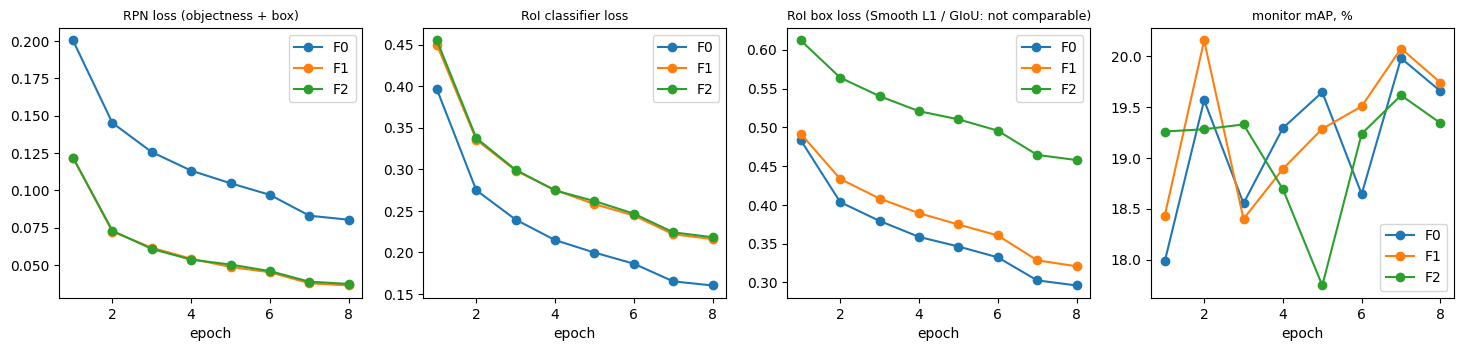

In [11]:
# Training dynamics: losses and monitor mAP after every epoch
hist = {n: pd.read_csv(RUNS_DIR / n / "history.csv") for n in EXPERIMENTS if (RUNS_DIR / n / "history.csv").exists()}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for n, h in hist.items():
    ax[0].plot(h.epoch, h.loss_objectness + h.loss_rpn_box_reg, "o-", label=n)
    ax[1].plot(h.epoch, h.loss_classifier, "o-", label=n)
    ax[2].plot(h.epoch, h.loss_box_reg, "o-", label=n)
    ax[3].plot(h.epoch, h.mAP * 100, "o-", label=n)
for a, t in zip(ax, ["RPN loss (objectness + box)", "RoI classifier loss", "RoI box loss (Smooth L1 / GIoU: not comparable)", "monitor mAP, %"]):
    a.set_title(t, fontsize=9); a.set_xlabel("epoch"); a.legend()
fig.savefig(FIG_DIR / "frcnn_curves.png", bbox_inches="tight"); plt.show()

> **Observation.** Inference settings mattered more than retraining. With the same F0 weights, 500 detections and score threshold
> 0.001 add +1.6 mAP and raise AR500 from 25.9 to 36.9: the default 100 detections cut recall in dense
> frames. 3000 instead of 1000 proposals add another +0.4. Smaller anchors and GIoU did not
> improve mAP; GIoU helped bicycle and hurt truck. Curves: monitor mAP is already 18–20% after
> the first epoch and only fluctuates afterwards, so 8 epochs are enough for a COCO-pretrained model. F1 and F2 have
> a much lower RPN loss, but this did not turn into higher mAP.

## 5. What each stage contributes
The RPN proposes class-agnostic boxes; the second stage (RoI head) classifies each proposal and refines its box.
The second stage cannot recover an object that no proposal covers, so the RPN's recall is an upper bound.
Below: share of ground-truth objects covered by at least one of the top-N proposals (IoU ≥ 0.5),
next to the share covered by a final confident detection of the right class.

In [12]:
BEST_RUN = max(EXPERIMENTS, key=lambda n: max((log.data[k]["metrics"]["mAP"] for k in log.data if k.startswith(n + " |")), default=-1))
BEST_KEY = max((k for k in log.data if k.startswith(BEST_RUN + " |")), key=lambda k: log.data[k]["metrics"]["mAP"])
BEST_INF = BEST_KEY.split(" | ")[1]
print("best:", BEST_KEY)

model = TV.build_faster_rcnn(cfgs[BEST_RUN]).to(DEVICE)
model.load_state_dict(torch.load(RUNS_DIR / BEST_RUN / "final.pth", map_location=DEVICE))
rpn_rec = TV.proposal_recall(model, val, DEVICE, n_list=(100, 300, 1000, 3000), max_images=50 if SMOKE else 300)

best_preds = pd.read_csv(RUNS_DIR / BEST_RUN / f"val_preds_{list(INFERENCE).index(BEST_INF)}.csv.gz")
err = AN.error_breakdown(best_preds, val, score_thr=0.3)
final_rec = (1 - err["misses"]["miss_rate_%"] / 100).rename("final detections (score ≥ 0.3)")
display((rpn_rec * 100).round(1))
display((final_rec * 100).round(1).to_frame().T)

best: F0 | 500 det, score 0.001, 3000 prop.


proposal recall:   0%|          | 0/300 [00:00<?, ?it/s]

,all,<16px,16-32px,32-96px,>96px
top-N proposals,,,,,
100,62.2,16.7,52.9,60.6,86.2
300,75.7,30.0,67.1,75.1,93.4
1000,84.8,50.0,76.1,85.0,97.4
3000,86.4,50.0,76.4,86.9,99.1


,<16px,16-32px,32-96px,>96px
final detections (score ≥ 0.3),15.8,45.0,61.1,83.1


> **Observation.** The RPN is not the bottleneck: 1000 proposals cover 84.8% of objects, and 3000 proposals add only 1.6 points. After the second stage, confident detections .find only 15.8%
> of objects below 16 px and 45% of 16–32 px objects. Most small objects are lost in the RoI head, which classifies a
> 7×7 feature crop of a region only a few pixels wide.

## 6. Failure analysis (best model)
Every confident detection is assigned one error type (see `vdet/analysis.py`), and every unmatched ground-truth
object counts as a miss. Then we look at concrete frames to find **at least three failure cases with plausible causes**.

In [14]:
display(err["detections"])
display(err["misses"])
display(err["miss_rate_by_class_%"].T)
err["confusions"].head(8)

,count,share_%
tp,68877,48.4
ignored,21792,15.3
background,18260,12.8
location,17946,12.6
class,14048,9.9
duplicate,1439,1.0


,gt,missed,miss_rate_%
<16px,425,358,84.2
16-32px,21506,11839,55.0
32-96px,79339,30881,38.9
>96px,12862,2177,16.9


cls,bus,tricycle,van,bicycle,motor,truck,car,person
miss_rate_%,98.5,63.1,62.0,57.7,53.8,43.5,36.1,30.3


,true,predicted,count
0,van,car,3104
1,motor,person,2365
2,bicycle,motor,1845
3,car,van,982
4,motor,bicycle,727
5,tricycle,motor,712
6,person,motor,549
7,tricycle,car,514


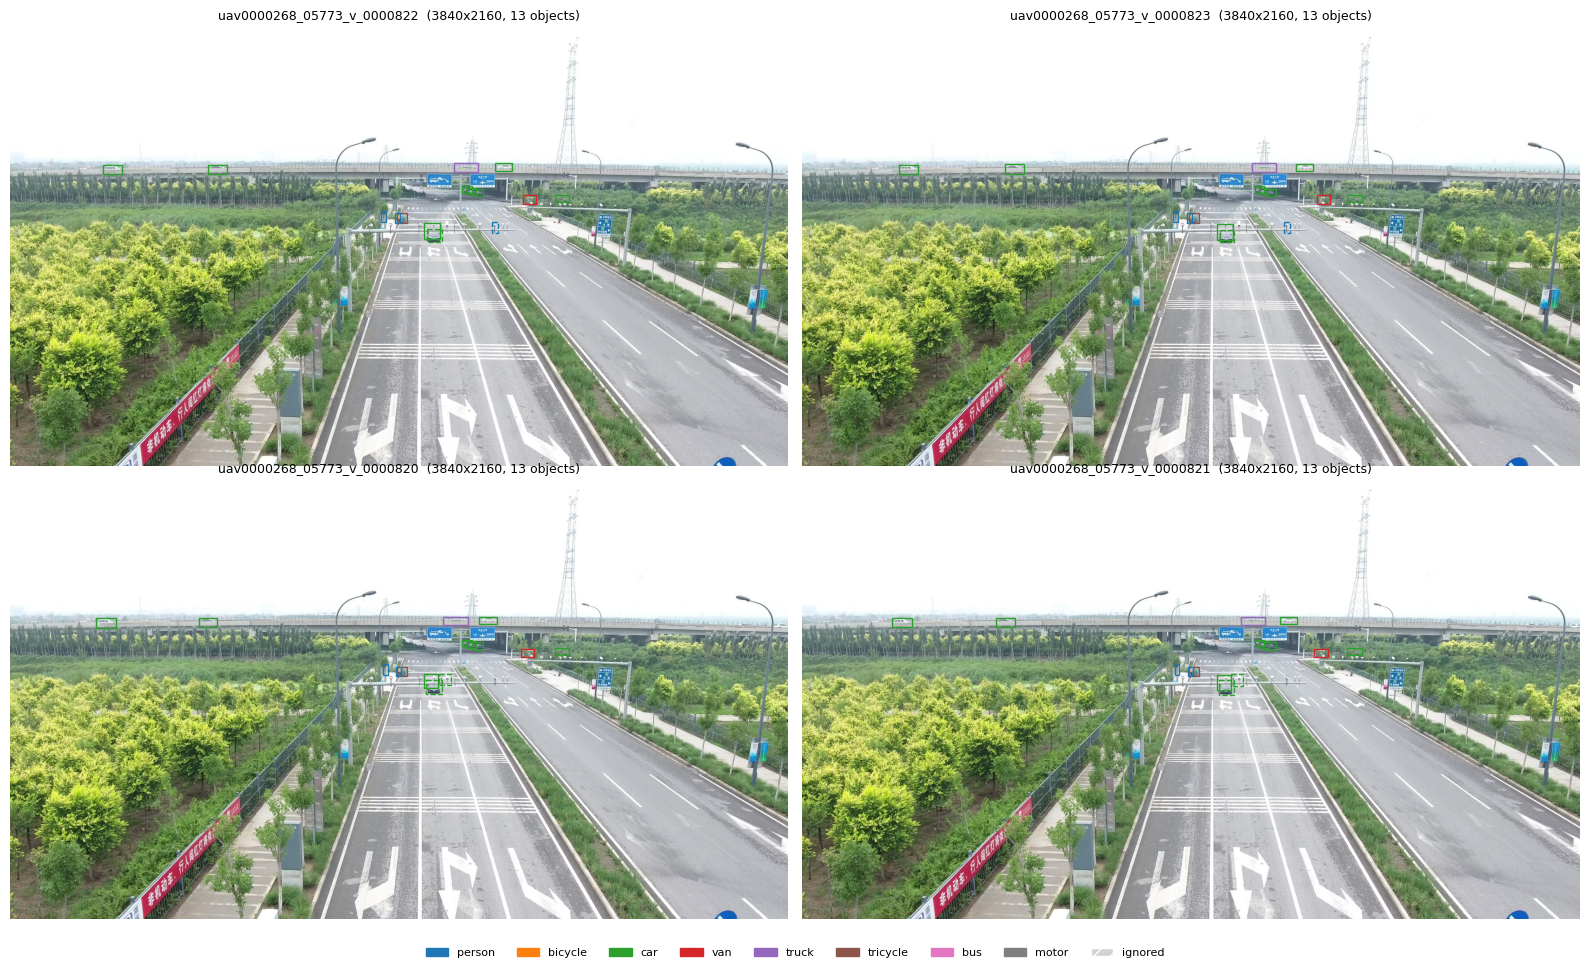

,key,gt,recall,false_pos
2230,uav0000268_05773_v_0000822,13,0.0,2
2231,uav0000268_05773_v_0000823,13,0.0,2
2228,uav0000268_05773_v_0000820,13,0.0,2
2229,uav0000268_05773_v_0000821,13,0.0,2


In [15]:
# The frames with the lowest recall, predictions dashed (score >= 0.3), ground truth solid
pf = err["per_frame"].dropna().sort_values("recall")
fig = V.show_frames(val, pf.key.iloc[:4].tolist(), preds=best_preds, score_thr=0.3, cols=2, size=8)
fig.savefig(FIG_DIR / "frcnn_worst_frames.png", bbox_inches="tight"); plt.show()
pf.head(4)

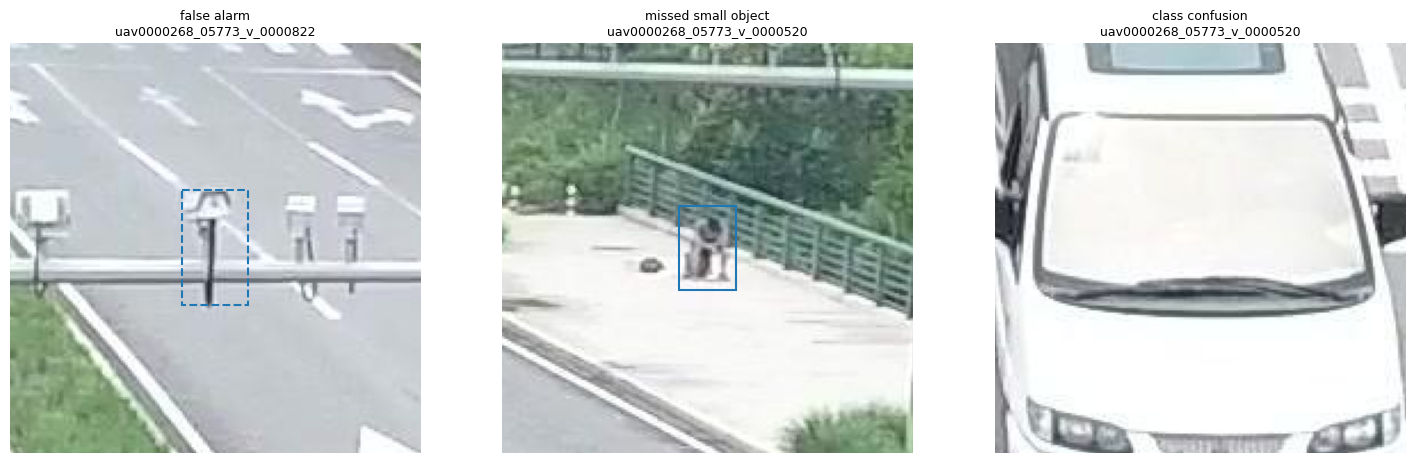

In [16]:
# Zoomed examples: a missed tiny object, a class confusion, a false alarm on background
from vdet.analysis import _iou_matrix
conf_p = best_preds[best_preds.score >= 0.3]
examples = []
for k in pf.key.iloc[:40]:
    g = val.boxes[val.boxes.key == k]; p = conf_p[conf_p.key == k]
    if len(g) == 0: continue
    iou = _iou_matrix(g[["x", "y", "w", "h"]].to_numpy(), p[["x", "y", "w", "h"]].to_numpy()) if len(p) else np.zeros((len(g), 0))
    best = iou.max(1) if iou.shape[1] else np.zeros(len(g))
    miss = g[(best < 0.1) & (g.w * g.h < 32 ** 2)]
    if len(miss) and not any(e[0] == "missed small object" for e in examples):
        r = miss.iloc[0]; examples.append(("missed small object", k, r.x + r.w / 2, r.y + r.h / 2))
    if len(p) and len(g):
        j = iou.argmax(0); ok = iou.max(0) >= 0.5
        wrong = p[ok & (p.cat.to_numpy() != g.cat.to_numpy()[j])]
        if len(wrong) and not any(e[0] == "class confusion" for e in examples):
            r = wrong.iloc[0]; examples.append(("class confusion", k, r.x + r.w / 2, r.y + r.h / 2))
        bg = p[iou.max(0) < 0.1] if iou.shape[0] else p
        if len(bg) and not any(e[0] == "false alarm" for e in examples):
            r = bg.iloc[0]; examples.append(("false alarm", k, r.x + r.w / 2, r.y + r.h / 2))
    if len(examples) == 3: break
fig, ax = plt.subplots(1, len(examples), figsize=(6 * len(examples), 6), squeeze=False)
for a, (kind, k, cx, cy) in zip(ax[0], examples):
    V.show_crop(a, val, k, cx, cy, half=90, preds=best_preds, score_thr=0.3, lw=1.5)
    a.set_title(f"{kind}\n{k}", fontsize=9)
fig.savefig(FIG_DIR / "frcnn_failure_cases.png", bbox_inches="tight"); plt.show()

> **Observation.** 48% of confident detections are correct; 15% fall into ignored regions (not penalised), 13% are background,
> 13% are badly localised and 10% have the wrong class. 84% of objects below 16 px and 55% of 16–32 px objects are
> missed. Bus is almost never found (98.5% missed: only 264 val objects, absent from most training clips). Main
> confusions: van → car (3104), motor → person (2365, the rider), bicycle → motor (1845). Failure cases:
> (1) the worst frames are from the 4K clip uav0000268, where distant cars become tiny after downscaling (recall 0);
> (2) a crouching person on the bridge is missed (small object, unusual pose);
> (3) a white minivan (van) is detected as car, because from above the two look alike;
> plus a false alarm on a traffic-camera pole that looks like a person.

## 7. Test predictions and submission (best run and test-time setting)

In [17]:
test = D.load_test_images(DATA_ROOT)
if SMOKE:
    test = test.groupby("clip").head(2)
TV.set_inference_params(model, **INFERENCE[BEST_INF])
test_preds, sec = TV.predict_table(model, test, DEVICE, batch=BATCH, workers=WORKERS, desc="test")
test_preds.to_csv(WORK_DIR / f"test_preds_frcnn_{BEST_RUN}.csv.gz", index=False)
if not SMOKE:
    sub = S.write_submission(test_preds, DATA_ROOT, WORK_DIR / f"submission_frcnn_{BEST_RUN}.csv")
    display(sub.head(3))
print(f"{len(test_preds)} detections on {test.key.nunique()} test frames, {sec*1000:.0f} ms/img")

test:   0%|          | 0/953 [00:00<?, ?it/s]

saved /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/submission_frcnn_F0.csv: 3811 rows, 1520461 detections, 0 empty rows


,image_id,PredictionString
0,clip_001_0000001,0 0.9991 783.2 889.3 61.1 165.5 0 0.9976 630.5...
1,clip_001_0000002,0 0.9986 776.9 891.5 64.8 166.9 0 0.9964 718.9...
2,clip_001_0000003,0 0.9977 771.3 897.7 65.3 166.7 0 0.9967 713.8...


1520499 detections on 3811 test frames, 104 ms/img


## 8. Summary

The RPN supplies candidates (85% of objects covered by 1000 proposals); the second stage decides the class and
refines the box, and most small objects are lost there. The biggest gain came from inference settings (500
detections, score 0.001, 3000 proposals: 17.8 → 19.8 mAP). Smaller anchors and GIoU did not help: the second stage
corrects the box shape anyway, so the anchor fit matters less, and GIoU lowered truck AP. Failure cases: tiny
distant objects in downscaled 4K frames, unusual poses, van/car and motor/person confusions. **F0 with 500
detections, score 0.001 and 3000 proposals goes forward:** 19.8 mAP, AP_small 9.7, AP_large 36.1, 151 ms/img,
public LB 0.2417.